# CDS 303 -  Final Project 2: Data Integration and PCA

# Team members 
-Donghyeok Kim
-Dongjun Lee

## Dataset
- Primary: Inside Airbnb, New York City listings, 14 September 2026 snapshot (http://insideairbnb.com/get-the-data/)
- Supplementary: NYC Department of City Planning, 2020-2024 ACS 5-year estimates by Neighborhood Tabulation Area (NTA), Economic and Housing files


## Description
`Project2_Integration_PCA.ipynb` merges the two datasets and writes `data/listings_merged.csv`. This notebook reads that file and runs PCA. Each row is one Airbnb listing with a price, together with the ACS values of the NTA where it is located.
Clustering and classification are not performed here.


In [28]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

# data mining
from sklearn.decomposition import PCA

# visualization
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

import warnings
warnings.filterwarnings(action = 'ignore')

In [29]:
import pandas as pd

df = pd.read_csv("data/listings_merged.csv")
df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,...,license,GeoID,poverty_pct,unemployment_pct,transit_commute_pct,median_hh_income,owner_occupied_pct,crowding_pct,rent_burden_pct,median_gross_rent
0,2539,11 Min to Manhattan • Prospect Park • Fast WiFi,2787,1462506323032802005,John,Brooklyn,Kensington,40.645940,-73.972160,Private room,...,NaN,BK1203,14.714629,5.129726,40.144866,88730.12228739003,33.5,13.5,51.2,1931.0
1,6848,Only 2 stops to Manhattan studio,15991,1462506783043501110,Allen,Brooklyn,Williamsburg,40.709350,-73.953420,Entire home/apt,...,NaN,BK0102,13.079101,5.955783,46.058255,148881.6924528302,16.2,7.6,37.2,3283.0
2,6990,UES Beautiful Blue Room,16800,1462506839076305525,Cynthia,Manhattan,East Harlem,40.787780,-73.947590,Private room,...,NaN,MN1101,30.632916,10.450406,56.678569,40653.4651810585,7.5,7.7,52.3,1295.0
3,7097,"Perfect for Your Parents, With Garden & Patio",17571,1462506848265336113,Jane,Brooklyn,Fort Greene,40.691940,-73.973890,Private room,...,NaN,BK0203,16.669286,9.321859,42.489171,115466.00719424461,20.3,7.7,41.9,2373.0
4,7801,Sunny Williamsburg Loft with Private Cedar Sauna,21207,1462506951310744838,Chaya,Brooklyn,Williamsburg,40.718807,-73.956177,Entire home/apt,...,NaN,BK0102,13.079101,5.955783,46.058255,148881.6924528302,16.2,7.6,37.2,3283.0


In [30]:
# median_hh_income was read as text because top-coded NTAs are stored as "200,000"; convert to numeric
df['median_hh_income'] = pd.to_numeric(df['median_hh_income'].astype(str).str.replace(',', ''))

In [31]:
print(f"Rows: {df.shape[0]:,}, Columns: {df.shape[1]}")

Rows: 19,331, Columns: 28


In [32]:
df.columns.tolist()

['id',
 'name',
 'host_id',
 'host_profile_id',
 'host_name',
 'neighbourhood_group',
 'neighbourhood',
 'latitude',
 'longitude',
 'room_type',
 'price',
 'minimum_nights',
 'number_of_reviews',
 'last_review',
 'reviews_per_month',
 'calculated_host_listings_count',
 'availability_365',
 'number_of_reviews_ltm',
 'license',
 'GeoID',
 'poverty_pct',
 'unemployment_pct',
 'transit_commute_pct',
 'median_hh_income',
 'owner_occupied_pct',
 'crowding_pct',
 'rent_burden_pct',
 'median_gross_rent']

In [33]:
df.dtypes

id                                  int64
name                               object
host_id                             int64
host_profile_id                     int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                             float64
minimum_nights                    float64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
number_of_reviews_ltm               int64
license                            object
GeoID                              object
poverty_pct                       float64
unemployment_pct                  float64
transit_commute_pct               float64
median_hh_income                  

In [34]:
df.describe()

,id,host_id,host_profile_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,poverty_pct,unemployment_pct,transit_commute_pct,median_hh_income,owner_occupied_pct,crowding_pct,rent_burden_pct,median_gross_rent
count,1.933100e+04,1.933100e+04,1.933100e+04,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,14286.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.000000,19331.00000,19331.000000
mean,7.679542e+17,1.746600e+16,1.475375e+18,40.727486,-73.943596,310.212612,23.675857,41.685324,1.220131,29.142672,253.491904,7.139310,16.116763,7.434694,44.135604,105595.715140,28.585991,6.974000,48.96427,2285.145673
std,6.318432e+17,1.721557e+17,4.098079e+16,0.058839,0.062294,574.415480,18.804740,96.590876,2.987486,71.404650,102.269211,24.689182,7.524246,2.607502,9.919794,43507.966882,14.857766,4.297839,6.76288,705.291057
min,2.539000e+03,1.678000e+03,1.462506e+18,40.504560,-74.251907,18.000000,1.000000,0.000000,0.010000,1.000000,0.000000,0.000000,4.780532,2.316873,10.048960,28468.714970,1.700000,1.600000,31.20000,1020.000000
25%,4.540887e+07,3.028359e+07,1.462987e+18,40.685015,-73.984250,104.000000,3.000000,0.000000,0.160000,1.000000,179.000000,0.000000,10.429144,5.583642,36.348763,75023.335848,18.000000,3.900000,43.60000,1755.000000
50%,8.383944e+17,1.744941e+08,1.466989e+18,40.730140,-73.954468,183.000000,30.000000,6.000000,0.430000,3.000000,276.000000,0.000000,13.079101,6.991757,45.133588,90745.701068,26.300000,5.900000,47.90000,2037.000000
75%,1.318512e+18,4.575110e+08,1.469999e+18,40.762964,-73.921462,337.000000,30.000000,43.000000,1.400000,13.000000,344.000000,3.000000,21.906339,9.062961,52.050809,140381.011375,35.700000,8.450000,53.20000,2937.000000
max,1.773595e+18,1.768961e+18,1.772764e+18,40.911147,-73.713650,31538.000000,365.000000,4894.000000,146.870000,889.000000,365.000000,1174.000000,47.636988,18.116756,69.010027,200000.000000,85.400000,30.300000,69.80000,3500.000000


In [35]:
df.isnull().sum()

id                                    0
name                                  0
host_id                               0
host_profile_id                       0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                        5045
reviews_per_month                  5045
calculated_host_listings_count        0
availability_365                      0
number_of_reviews_ltm                 0
license                           14754
GeoID                                 0
poverty_pct                           0
unemployment_pct                      0
transit_commute_pct                   0
median_hh_income                      0
owner_occupied_pct                    0


## Initial Observations
- Listings without a price (about one third of the raw data) and listings that could not be matched to a neighborhood were already removed when the files were merged, so `price` has no missing values here (19,331 listings).
- `last_review` and `reviews_per_month` are missing for the same 5,045 listings — these are listings with zero reviews. `license` is missing for 14,754 listings.
- The median minimum stay is 30 nights, likely reflecting NYC's short-term rental regulations.
- Prices are heavily right-skewed (median $183 vs. mean $310 and max $31,538), so median is a better summary than mean.
- The new neighborhood variables are complete for every listing. Within them, `median_hh_income` and `median_gross_rent` move together, and both move opposite to `poverty_pct`, `unemployment_pct` and `rent_burden_pct`.

In [36]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

NYC = df[['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month',
          'calculated_host_listings_count', 'availability_365',
          'poverty_pct', 'unemployment_pct', 'transit_commute_pct',
          'median_hh_income', 'owner_occupied_pct', 'crowding_pct',
          'rent_burden_pct', 'median_gross_rent']]
print(NYC.shape, NYC.isnull().sum().sum())

(19331, 14) 0


In [37]:
NYC_st = StandardScaler().fit_transform(NYC)
NYC_st = pd.DataFrame(NYC_st, columns = NYC.columns)
NYC_st.head(10)

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,poverty_pct,unemployment_pct,transit_commute_pct,median_hh_income,owner_occupied_pct,crowding_pct,rent_burden_pct,median_gross_rent
0,-0.386860,0.336314,-0.328045,-0.313214,-0.366129,0.630784,-0.186354,-0.883998,-0.402311,-0.387654,0.330745,1.518477,0.330597,-0.502140
1,-0.334632,0.336314,1.639065,0.018410,-0.394140,0.298319,-0.403727,-0.567190,0.193825,0.994923,-0.833659,0.145658,-1.739580,1.414849
2,-0.421679,0.336314,2.156726,0.121328,-0.394140,0.288541,1.929300,1.156582,1.264471,-1.492691,-1.419227,0.168926,0.493254,-1.403919
3,-0.183169,0.336314,3.947832,0.452953,-0.380135,-0.542620,0.073434,0.723763,-0.165979,0.226868,-0.557702,0.168926,-1.044592,0.124568
4,0.138905,0.336314,-0.286632,-0.317026,-0.394140,-1.823586,-0.403727,-0.567190,0.193825,0.994923,-0.833659,0.145658,-1.739580,1.414849
5,-0.038671,-1.152710,1.525180,0.003163,-0.380135,0.004968,1.252983,0.909280,0.561019,-0.702703,-0.180785,-0.436044,0.626337,-0.521990
6,-0.306776,0.336314,0.179263,-0.233167,-0.394140,-1.002203,-0.516694,-0.491275,-0.963365,0.031797,-0.860582,-0.715262,-0.305243,0.182701
7,-0.419938,0.336314,0.417386,-0.187426,-0.324114,-0.180821,1.309708,0.244010,0.359814,-0.380293,-0.705777,0.820433,-0.201734,-0.066847
8,-0.346818,0.336314,-0.296985,-0.297967,-0.394140,-1.647576,0.385845,0.143969,0.330385,-0.703285,-0.375974,-0.249900,0.123579,-0.848105
9,0.030967,-1.205890,4.672557,0.605424,-0.394140,0.014747,-1.090171,-1.441388,0.905366,1.617225,-0.497126,0.494680,-2.050107,1.722531


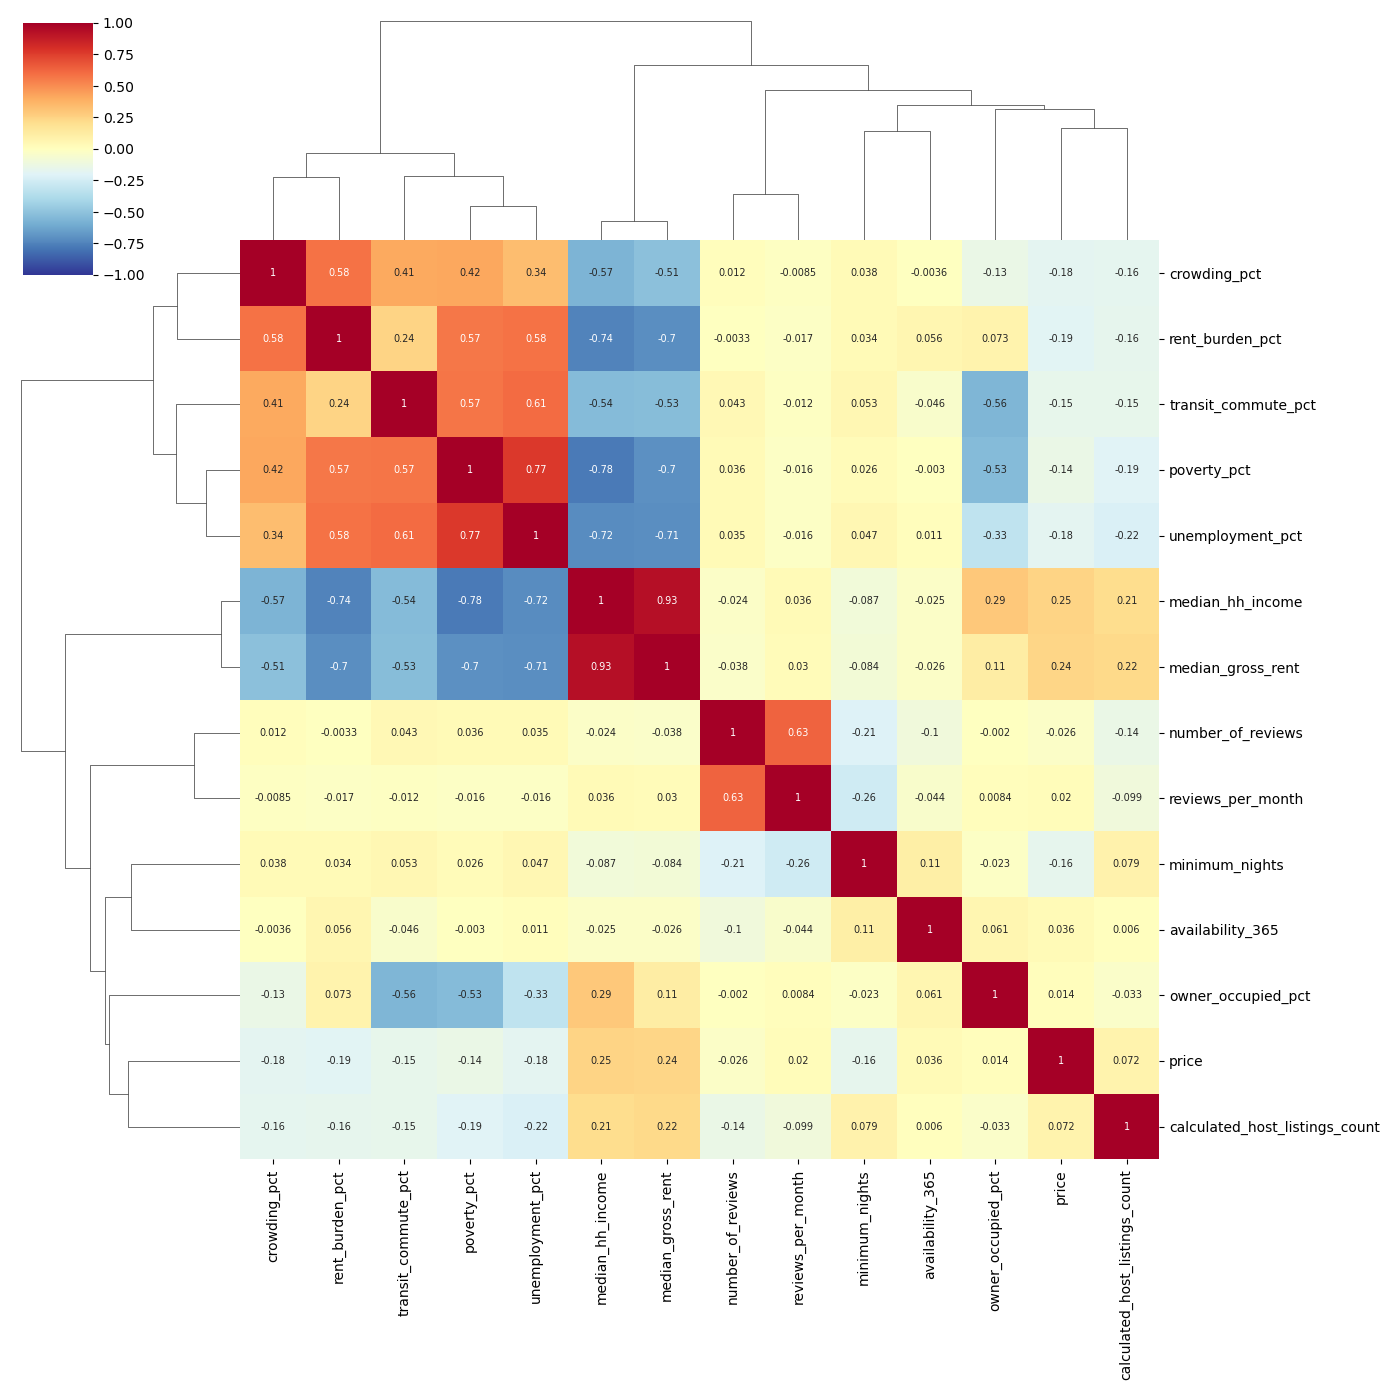

In [38]:
cor = NYC_st.corr()

sns.clustermap(cor, annot = True, cmap = 'RdYlBu_r',vmin = -1, vmax = 1,figsize=(14,14), annot_kws={'size': 7})
plt.show()

In [39]:
pca = PCA(random_state = 2000, n_components = None)
pca.fit_transform(NYC_st)

array([[-0.42925129, -0.64115639,  1.25614371, ..., -0.20069432,
         0.02393871,  0.1374019 ],
       [ 1.56120336,  0.98835698, -1.30096138, ..., -0.42662607,
        -0.01716996, -0.22289245],
       [-3.41180487,  1.29672614, -1.01141514, ...,  0.04067163,
         0.24487576,  0.03039402],
       ...,
       [ 2.12132821, -0.90184578, -0.60013055, ...,  0.14589251,
        -0.03694152,  0.07645736],
       [ 2.31580699, -0.68895808,  0.48239158, ...,  0.54806246,
        -0.20201296, -0.24622887],
       [ 2.53727104, -1.38359793, -0.73929057, ...,  0.05883285,
         0.57286045,  0.12836385]], shape=(19331, 14))

In [40]:
pca.explained_variance_

array([4.91060717, 1.84063799, 1.45166073, 1.03784796, 0.98527422,
       0.89791908, 0.72092434, 0.69165514, 0.43673475, 0.36396312,
       0.30783107, 0.18303495, 0.13634177, 0.03629196])

In [41]:
pca.explained_variance_ratio_

array([0.35073951, 0.13146734, 0.10368469, 0.07412816, 0.07037309,
       0.06413376, 0.05149193, 0.04940138, 0.03119373, 0.02599602,
       0.0219868 , 0.01307325, 0.00973819, 0.00259215])

In [42]:
exp_variance_ratio = pca.explained_variance_ratio_

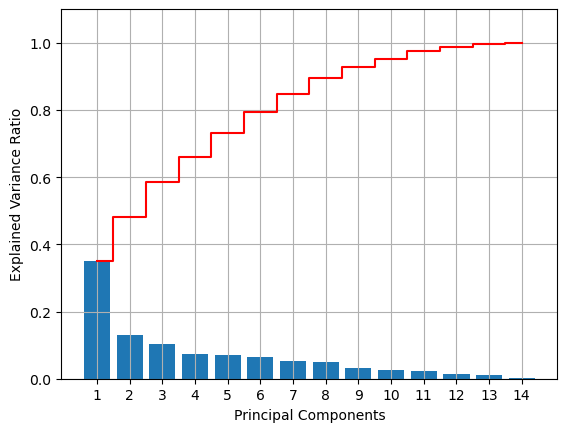

In [43]:
def explained_variance_ratio_plot(exp_variance_ratio):
    x_axis = range(1, len(exp_variance_ratio)+1)
    plt.bar(x_axis, exp_variance_ratio,
            align = 'center', label = 'Individual Explained Variance Ratio')
    plt.step(x_axis, np.cumsum(exp_variance_ratio),
             where = 'mid', color='red', label='Cumulative Explained Variance Ratio')
    plt.ylim(0, 1.1)
    plt.xticks(x_axis)
    plt.xlabel('Principal Components')
    plt.ylabel('Explained Variance Ratio')
    plt.grid()
    plt.show()

explained_variance_ratio_plot(exp_variance_ratio)

In [44]:
loadings = pca.components_

In [45]:
num_pc = pca.components_.shape[1]
pc_list = ["PC"+str(i) for i in list(range(1, num_pc+1))]

loadings_df = pd.DataFrame.from_dict(dict(zip(pc_list, loadings)))
loadings_df['variable'] = NYC.columns.values
loadings_df = loadings_df.set_index('variable')
loadings_df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14
variable,,,,,,,,,,,,,,
price,0.128792,0.057377,-0.171353,0.759258,-0.129405,0.079664,0.563300,0.157333,0.083085,-0.010115,-0.035954,-0.001413,-0.026442,-0.011584
minimum_nights,-0.038970,-0.402233,0.028076,-0.415292,0.392441,-0.038156,0.691717,0.132351,-0.070578,0.073080,0.034291,0.007352,0.020466,0.002919
number_of_reviews,-0.018871,0.616040,0.035340,-0.172759,0.228693,0.108354,0.202118,0.003531,0.108224,-0.669652,0.148377,0.040386,-0.018607,0.000341
reviews_per_month,0.010819,0.621011,0.043133,-0.071662,0.262340,0.163882,0.089224,0.051571,-0.125894,0.681447,-0.138170,-0.036486,0.016266,-0.005109
calculated_host_listings_count,0.123768,-0.202794,-0.182561,-0.055060,0.073290,0.926160,-0.095466,-0.091178,0.137596,-0.015644,0.032407,-0.073864,0.025759,-0.016656
availability_365,-0.003538,-0.161381,0.174172,0.416895,0.810929,-0.074230,-0.313701,0.047518,0.032644,-0.069837,0.006587,-0.005075,0.001563,0.003030
poverty_pct,-0.392070,0.016569,-0.189837,0.108004,0.017922,0.020332,0.032560,-0.188125,-0.387093,-0.073640,0.082524,-0.261653,0.728124,-0.020435
unemployment_pct,-0.380173,0.012195,-0.080073,0.074306,0.027455,-0.047138,0.073057,-0.372528,0.159765,0.165887,0.581734,-0.348684,-0.426361,-0.038407
transit_commute_pct,-0.315918,0.023228,-0.384386,-0.067947,0.058590,-0.107903,-0.068043,0.209239,0.682459,0.143234,0.048064,0.324918,0.283835,-0.095342


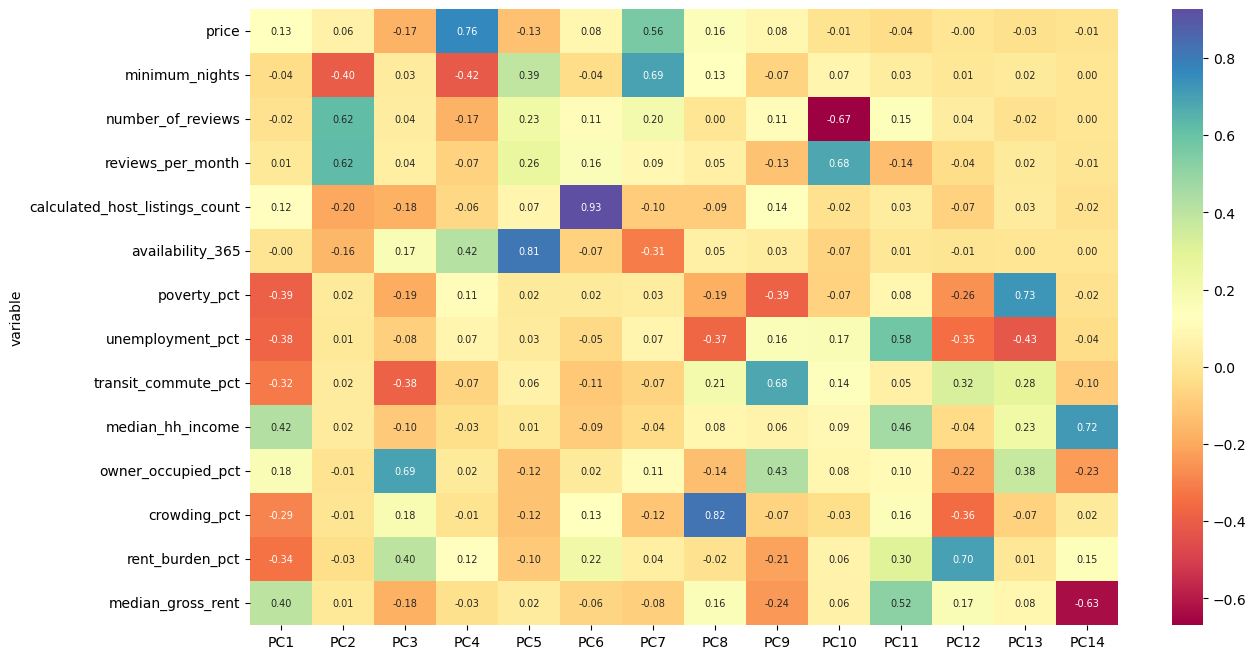

In [46]:
plt.figure(figsize=(14, 8))
ax = sns.heatmap(loadings_df, annot=True, fmt='.2f', annot_kws={'size': 7}, cmap='Spectral')
plt.show()
# can browse characteristics of each principal component

In [47]:
pca.transform(NYC_st)

array([[-0.42925129, -0.64115639,  1.25614371, ..., -0.20069432,
         0.02393871,  0.1374019 ],
       [ 1.56120336,  0.98835698, -1.30096138, ..., -0.42662607,
        -0.01716996, -0.22289245],
       [-3.41180487,  1.29672614, -1.01141514, ...,  0.04067163,
         0.24487576,  0.03039402],
       ...,
       [ 2.12132821, -0.90184578, -0.60013055, ...,  0.14589251,
        -0.03694152,  0.07645736],
       [ 2.31580699, -0.68895808,  0.48239158, ...,  0.54806246,
        -0.20201296, -0.24622887],
       [ 2.53727104, -1.38359793, -0.73929057, ...,  0.05883285,
         0.57286045,  0.12836385]], shape=(19331, 14))

In [48]:
scores = pca.transform(NYC_st).transpose()

In [49]:
# explained variance ratio and cumulative ratio for each component
variance_table = pd.DataFrame({
    'explained_variance_ratio': exp_variance_ratio,
    'cumulative_ratio': np.cumsum(exp_variance_ratio)
}, index=pc_list)
print(variance_table.round(3))

# number of components needed to reach 80% of the total variance
n_retain = int(np.argmax(np.cumsum(exp_variance_ratio) >= 0.80) + 1)
print('Components retained:', n_retain)

      explained_variance_ratio  cumulative_ratio
PC1                      0.351             0.351
PC2                      0.131             0.482
PC3                      0.104             0.586
PC4                      0.074             0.660
PC5                      0.070             0.730
PC6                      0.064             0.795
PC7                      0.051             0.846
PC8                      0.049             0.895
PC9                      0.031             0.927
PC10                     0.026             0.953
PC11                     0.022             0.975
PC12                     0.013             0.988
PC13                     0.010             0.997
PC14                     0.003             1.000
Components retained: 7


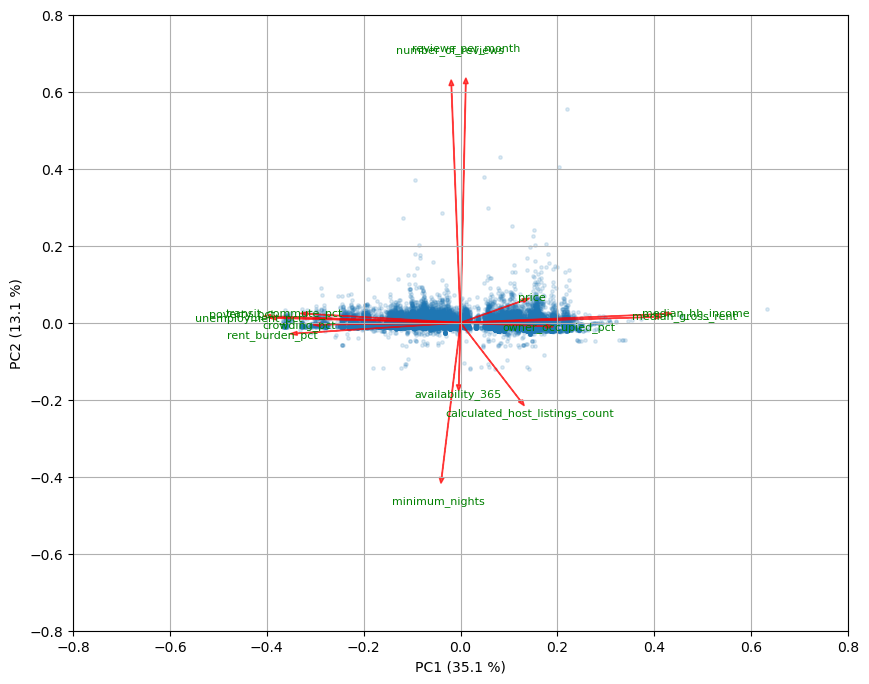

In [50]:
# biplot of the first two principal components (adapted from Demo 6)
def biplot(score, coeff, pcax, pcay, labels=None):
    pca1 = pcax - 1
    pca2 = pcay - 1
    xs = score[:, pca1]
    ys = score[:, pca2]
    n = coeff.shape[0]
    scalex = 1.0 / (xs.max() - xs.min())
    scaley = 1.0 / (ys.max() - ys.min())
    plt.figure(figsize=(10, 8))
    plt.scatter(xs * scalex, ys * scaley, alpha=0.15, s=6)
    for i in range(n):
        plt.arrow(0, 0, coeff[i, pca1], coeff[i, pca2], color='r', alpha=0.7, head_width=0.01)
        name = 'Var' + str(i + 1) if labels is None else labels[i]
        plt.text(coeff[i, pca1] * 1.15, coeff[i, pca2] * 1.15, name,
                 color='g', ha='center', va='center', fontsize=8)
    plt.xlim(-0.8, 0.8)
    plt.ylim(-0.8, 0.8)
    plt.xlabel('PC{} ({:.1f} %)'.format(pcax, pca.explained_variance_ratio_[pca1] * 100))
    plt.ylabel('PC{} ({:.1f} %)'.format(pcay, pca.explained_variance_ratio_[pca2] * 100))
    plt.grid()
    plt.savefig('biplot_pc1_pc2.png', dpi=150, bbox_inches='tight')
    plt.show()

biplot(pca.transform(NYC_st), pca.components_.T, 1, 2, labels=NYC.columns)

## PCA Observations
- 19,331 listings and 14 variables were used. `latitude`, `longitude` and identifiers were excluded, and missing `reviews_per_month` values (listings with zero reviews) were set to 0.
- PC1 explains 35.1% of the variance, PC2 13.1% and PC3 10.4%. Six components reach 79.5% and seven reach 84.6%, so we retain seven components (80% threshold).
- PC1 is a neighborhood affluence axis: positive on `median_hh_income` and `median_gross_rent`, negative on `poverty_pct`, `unemployment_pct`, `rent_burden_pct` and `transit_commute_pct`.
- PC2 is a review-activity axis: positive on `number_of_reviews` and `reviews_per_month`, negative on `minimum_nights`.
- PC3 is mostly `owner_occupied_pct`, PC4 is mostly `price`, PC5 is mostly `availability_365` and PC6 is mostly `calculated_host_listings_count`.

### Biplot (PC1 and PC2)
- The arrows form two nearly perpendicular bundles. The neighborhood variables lie along PC1: income and rent point right, while poverty, unemployment, crowding, rent burden and transit commuting point left.
- The review variables point up and `minimum_nights` points down along PC2.
- Because the two bundles are close to perpendicular, how actively a listing is reviewed is largely unrelated to how affluent its neighborhood is.
- Most points lie in a flat band because a few listings with very many reviews stretch the PC2 axis. The skewed variables were not log-transformed.
- PCA shows directions of variation, not clusters. Denser areas in the plot are not interpreted as groups.